# Deep Learning for Computer Vision: CIFAR-10 Transfer Learning & Multi-Task Pet Localization

This notebook presents an end-to-end experimental study across two fundamental computer vision tasks implemented in **TensorFlow / Keras**:

1. **Multi-Class Image Classification & Transfer Learning (CIFAR-10):** A controlled benchmark comparing a custom 3-block VGG-style CNN trained from scratch against an ImageNet-pretrained **MobileNetV2** backbone under both frozen feature-extraction and selective upper-layer fine-tuning regimes.
2. **Multi-Task Object Localization & Species Classification (Oxford-IIIT Pet):** A dual-head MobileNetV2 network trained jointly with weighted Mean Squared Error (`MSE`) and Binary Cross-Entropy (`BCE`) losses to simultaneously regress normalized head bounding-box coordinates `[xmin, ymin, xmax, ymax]` and classify pet species (`Cat` vs. `Dog`).

> **Environment:** Python 3.10+, TensorFlow 2.15+, TensorFlow Datasets, scikit-learn, NumPy, pandas, Matplotlib.

## Experimental Scope & Methodology

- **Data Integrity & Splitting:** Stratified train/validation/test partitioning to preserve class priors and prevent data leakage.
- **Input Pipelines:** Asynchronous `tf.data` pipelines with normalization, `AUTOTUNE` prefetching, and training-only geometric augmentations.
- **Progressive Representation Learning:** Systematic comparison of from-scratch feature learning, frozen ImageNet transfer learning, and conservative (`lr = 1e-5`) upper-layer fine-tuning.
- **Multi-Task Localization Evaluation:** Quantitative assessment beyond classification accuracy using vectorized Intersection over Union (**IoU**) distributions and Precision / Recall / F1 across localization thresholds (`IoU >= 0.30, 0.50, 0.75`).

In [1]:
# Section 0: Global Environment Setup & Reproducibility Seeds
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

try:
    import tensorflow_datasets as tfds
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "tensorflow-datasets"])
    import tensorflow_datasets as tfds

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

AUTOTUNE = tf.data.AUTOTUNE
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))

# Execution mode flag: False runs full-dataset GPU training; True uses a stratified subset for rapid smoke testing.
QUICK_RUN = False

TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Part 1 — Multi-Class Image Classification Benchmark (CIFAR-10)

This section evaluates three convolutional architectures on the 10-class **CIFAR-10** benchmark (`50,000` training / `10,000` test RGB images at `32x32` resolution):

1. Stratified `80/20` train/validation partitioning (`40,000` train / `10,000` validation) while isolating the official `10,000`-image test split.
2. Exploratory class-balance verification and visual sample inspection.
3. GPU-prefetched `tf.data` pipelines with online geometric data augmentation.
4. **Model A — Custom VGG-Style CNN:** 3 convolutional stages (`32 -> 64 -> 128` filters) with BatchNormalization and progressive Dropout.
5. **Model B — Frozen MobileNetV2:** ImageNet feature extractor with spatial upsampling (`96x96`) and a custom classification head.
6. **Model C — Fine-Tuned MobileNetV2:** Selective unfreezing of the top 30 backbone layers trained at `lr = 1e-5`.

In [2]:
# Section 1.1: Load CIFAR-10 dataset and inspect tensor shapes & value ranges

CIFAR10_CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
                   'dog', 'frog', 'horse', 'ship', 'truck']
NUM_CLASSES = len(CIFAR10_CLASSES)

(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar10.load_data()

print(f"Full training set : {x_train_full.shape}, labels: {y_train_full.shape}")
print(f"Test set           : {x_test.shape}, labels: {y_test.shape}")
print(f"Pixel value range  : [{x_train_full.min()}, {x_train_full.max()}]")
print(f"Data type          : {x_train_full.dtype}")
print(f"Number of classes  : {NUM_CLASSES}")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step
Full training set : (50000, 32, 32, 3), labels: (50000, 1)
Test set           : (10000, 32, 32, 3), labels: (10000, 1)
Pixel value range  : [0, 255]
Data type          : uint8
Number of classes  : 10


In [3]:
# Section 1.2: Stratified train/validation split (80/20) with isolated official test set

from sklearn.model_selection import train_test_split

VAL_FRACTION = 0.2
BATCH_SIZE_CLF = 64

if QUICK_RUN:
    SUBSET_TRAIN = 5000
    SUBSET_VAL   = 1000
    SUBSET_TEST  = 2000
    EPOCHS_CLF   = 10
else:
    EPOCHS_CLF = 50

x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=VAL_FRACTION,
    stratify=y_train_full,
    random_state=SEED,
)

if QUICK_RUN:
    x_train, _, y_train, _ = train_test_split(
        x_train, y_train, train_size=SUBSET_TRAIN,
        stratify=y_train, random_state=SEED)
    x_val, _, y_val, _ = train_test_split(
        x_val, y_val, train_size=SUBSET_VAL,
        stratify=y_val, random_state=SEED)
    x_test_eval, _, y_test_eval, _ = train_test_split(
        x_test, y_test, train_size=SUBSET_TEST,
        stratify=y_test, random_state=SEED)
else:
    x_test_eval, y_test_eval = x_test, y_test

print(f"Train      : {x_train.shape}")
print(f"Validation : {x_val.shape}")
print(f"Test       : {x_test_eval.shape}")
print(f"Epochs     : {EPOCHS_CLF}")
print(f"Batch size : {BATCH_SIZE_CLF}")

Train      : (40000, 32, 32, 3)
Validation : (10000, 32, 32, 3)
Test       : (10000, 32, 32, 3)
Epochs     : 50
Batch size : 64


In [4]:
# Section 1.3: Verify class distribution and balance ratio across the training split

train_labels_flat = y_train.flatten()
class_counts = pd.DataFrame({
    'Class': CIFAR10_CLASSES,
    'Count': [np.sum(train_labels_flat == i) for i in range(NUM_CLASSES)],
})
class_counts['Percentage (%)'] = (class_counts['Count'] / len(train_labels_flat) * 100).round(2)

print("Class Distribution in Training Set")
print("=" * 42)
print(class_counts.to_string(index=False))
print("=" * 42)
print(f"Total samples : {len(train_labels_flat)}")
ratio = class_counts['Count'].min() / class_counts['Count'].max()
print(f"Min / Max ratio: {ratio:.4f}")
print(f"\nThe dataset is {'well-balanced' if ratio > 0.9 else 'slightly imbalanced'}.")

Class Distribution in Training Set
     Class  Count  Percentage (%)
  airplane   4000            10.0
automobile   4000            10.0
      bird   4000            10.0
       cat   4000            10.0
      deer   4000            10.0
       dog   4000            10.0
      frog   4000            10.0
     horse   4000            10.0
      ship   4000            10.0
     truck   4000            10.0
Total samples : 40000
Min / Max ratio: 1.0000

The dataset is well-balanced.


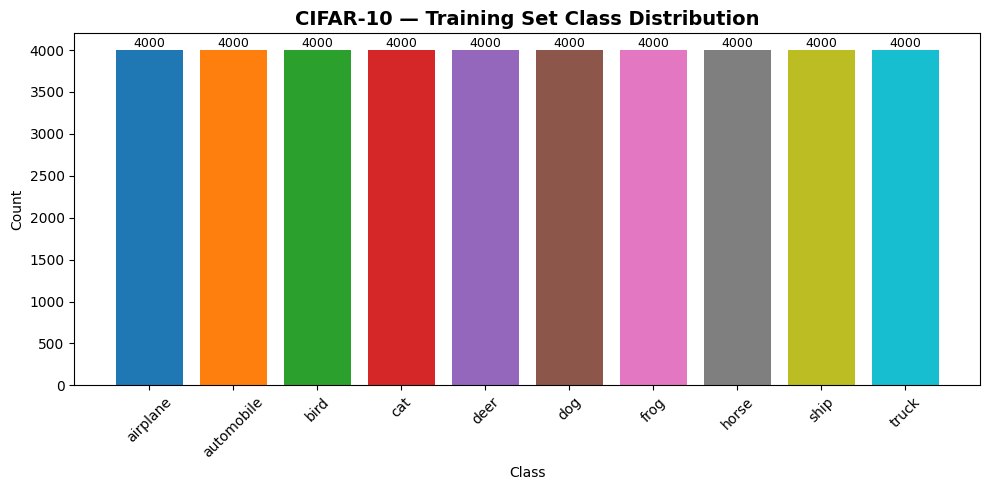

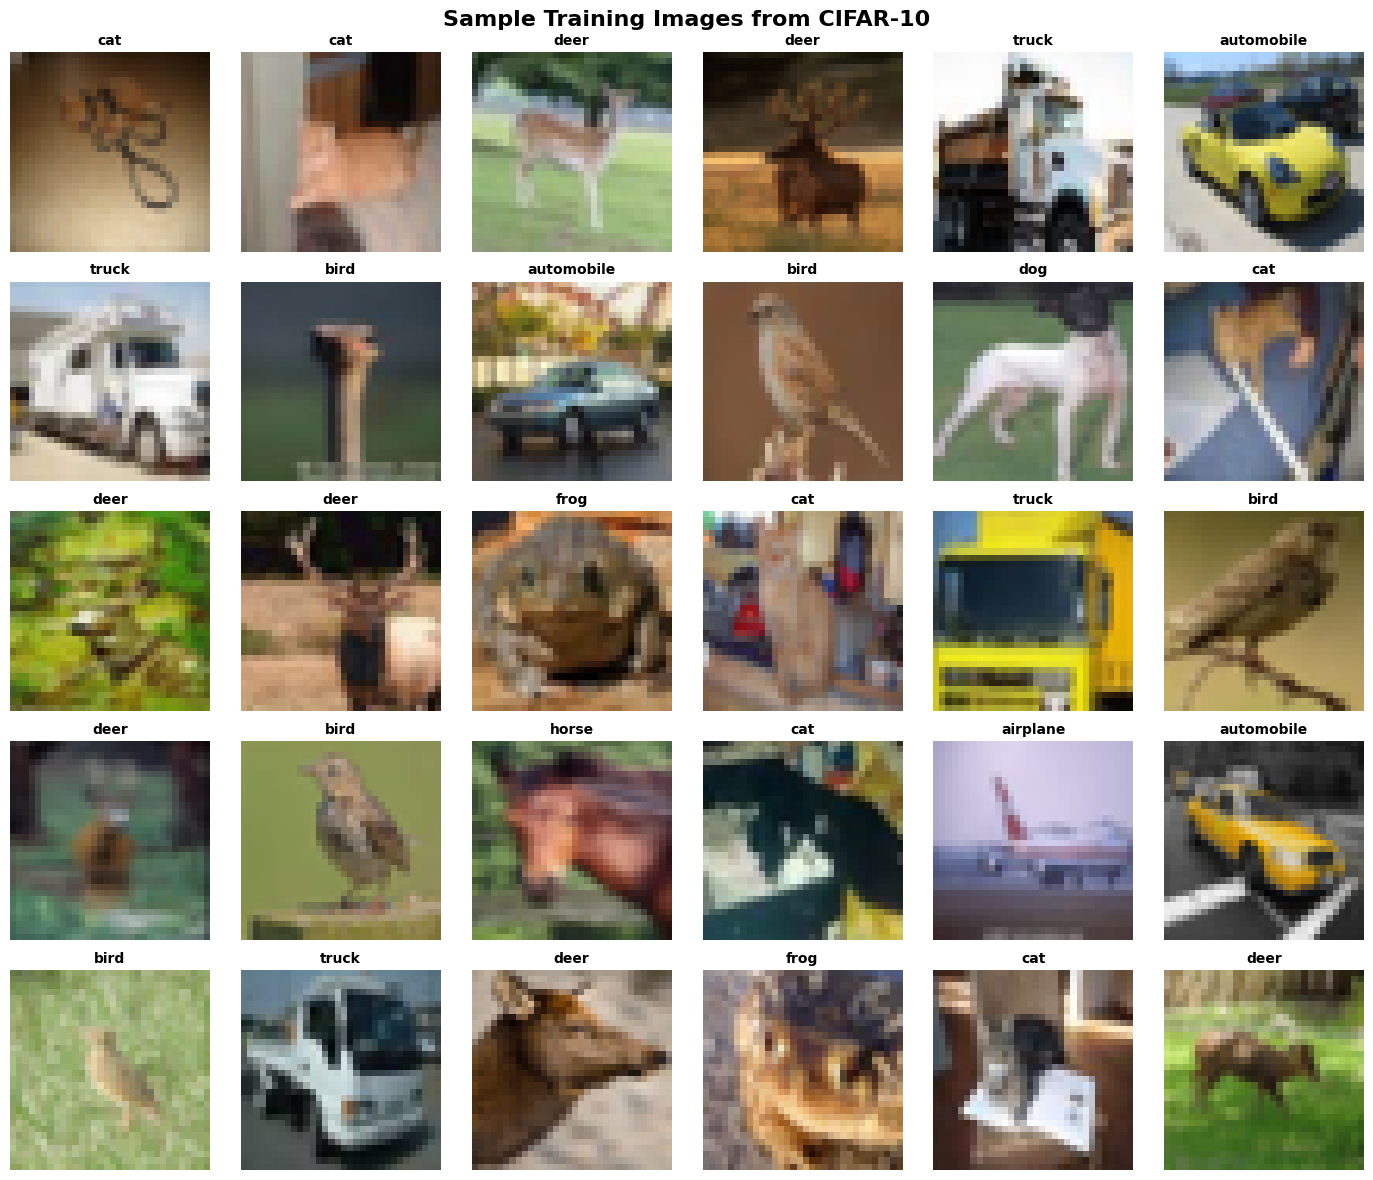

In [5]:
# Section 1.4: Visualize training class distribution and a 5x6 sample image grid

fig, ax = plt.subplots(figsize=(10, 5))
colors = plt.cm.tab10(np.arange(NUM_CLASSES))
bars = ax.bar(class_counts['Class'], class_counts['Count'], color=colors)
for bar, cnt in zip(bars, class_counts['Count']):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            str(cnt), ha='center', va='bottom', fontsize=9)
ax.set_title('CIFAR-10 — Training Set Class Distribution', fontsize=14, fontweight='bold')
ax.set_xlabel('Class')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# Sample images grid (5 x 6)
fig, axes = plt.subplots(5, 6, figsize=(14, 12))
for ax in axes.flat:
    idx = np.random.randint(len(x_train))
    ax.imshow(x_train[idx])
    ax.set_title(CIFAR10_CLASSES[y_train[idx, 0]], fontsize=10, fontweight='bold')
    ax.axis('off')
fig.suptitle('Sample Training Images from CIFAR-10', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [6]:
# Section 1.5: Build tf.data input pipelines with normalization and training-only augmentation

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
], name="data_augmentation")


def build_clf_dataset(images, labels, training=False, batch_size=BATCH_SIZE_CLF):
    images = tf.cast(images, tf.float32) / 255.0
    labels_oh = tf.one_hot(tf.cast(labels.flatten(), tf.int32), NUM_CLASSES)
    ds = tf.data.Dataset.from_tensor_slices((images, labels_oh))
    if training:
        ds = ds.shuffle(buffer_size=len(images), seed=SEED)
    ds = ds.batch(batch_size)
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                     num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


train_ds = build_clf_dataset(x_train, y_train, training=True)
val_ds   = build_clf_dataset(x_val,   y_val,   training=False)
test_ds  = build_clf_dataset(x_test_eval, y_test_eval, training=False)

for imgs, lbls in train_ds.take(1):
    print(f"Image batch shape : {imgs.shape}")
    print(f"Label batch shape : {lbls.shape}")
    print(f"Pixel range       : [{imgs.numpy().min():.3f}, {imgs.numpy().max():.3f}]")
    print(f"Label sum (sample): {lbls[0].numpy().sum():.1f}  (should be 1.0)")

Image batch shape : (64, 32, 32, 3)
Label batch shape : (64, 10)
Pixel range       : [0.001, 1.000]
Label sum (sample): 1.0  (should be 1.0)


In [7]:
# Section 1.6: Define Custom 3-block VGG-style CNN architecture with BatchNormalization & Dropout

def build_custom_cnn(input_shape=(32, 32, 3), num_classes=NUM_CLASSES):
    model = keras.Sequential([
        layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.2),

        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.3),

        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.4),

        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax'),
    ], name="custom_cnn")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model


cnn_model = build_custom_cnn()
cnn_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 816,938 (3.12 MB)

 Trainable params: 815,530 (3.11 MB)

 Non-trainable params: 1,408 (5.50 KB)

In [8]:
# Section 1.7: Train Custom CNN with EarlyStopping and ReduceLROnPlateau callbacks

cnn_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=7,
        restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5,
        patience=3, min_lr=1e-6, verbose=1),
]

print(f"Training Custom CNN for up to {EPOCHS_CLF} epochs ...")
cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_CLF,
    callbacks=cnn_callbacks,
    verbose=1,
)

Training Custom CNN for up to 50 epochs ...
Epoch 1/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 34s 27ms/step - accuracy: 0.3397 - loss: 1.9623 - val_accuracy: 0.4497 - val_loss: 1.5528 - learning_rate: 0.0010
Epoch 2/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.4566 - loss: 1.5021 - val_accuracy: 0.5121 - val_loss: 1.4196 - learning_rate: 0.0010
Epoch 3/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.5192 - loss: 1.3363 - val_accuracy: 0.5608 - val_loss: 1.2328 - learning_rate: 0.0010
Epoch 4/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.5577 - loss: 1.2349 - val_accuracy: 0.5620 - val_loss: 1.4097 - learning_rate: 0.0010
Epoch 5/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.5891 - loss: 1.1628 - val_accuracy: 0.6110 - val_loss: 1.1655 - learning_rate: 0.0010
Epoch 6/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.6062 - loss: 1.1106 - val_accuracy: 0.6500 - val_loss: 1.0160 - learning_rate: 0.0010
Epoch 7/50
625/625 ━━━━━━━━━━━━━

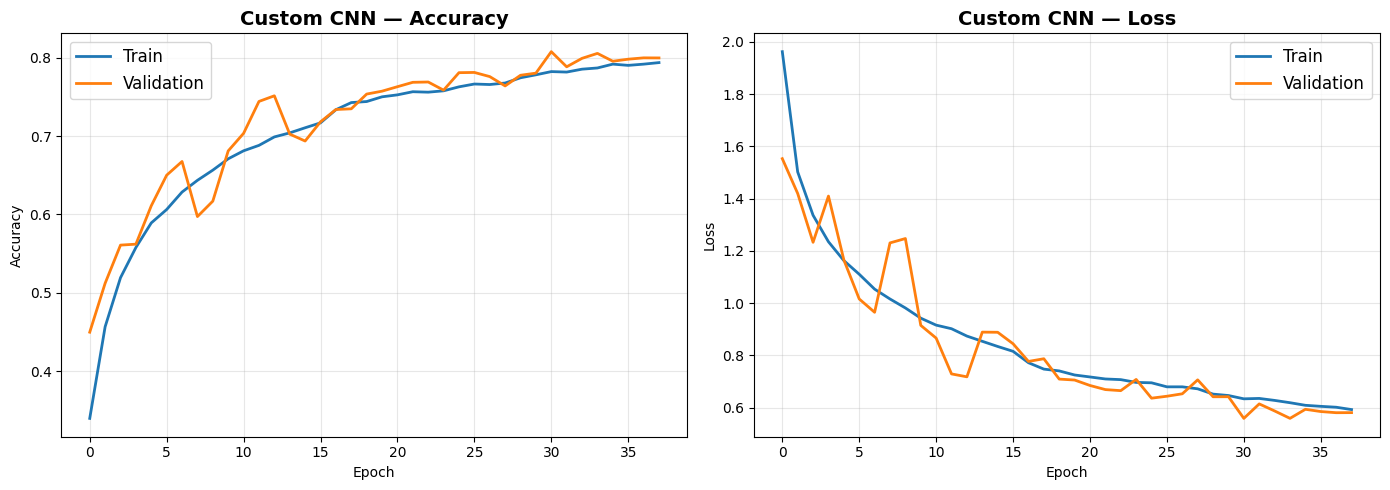

In [9]:
# Section 1.8: Plot training and validation accuracy/loss learning curves

def plot_training_curves(history, title="Model"):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    ax1.plot(history.history['accuracy'],     label='Train',      linewidth=2)
    ax1.plot(history.history['val_accuracy'],  label='Validation', linewidth=2)
    ax1.set_title(f'{title} — Accuracy', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy')
    ax1.legend(fontsize=12); ax1.grid(True, alpha=0.3)

    ax2.plot(history.history['loss'],     label='Train',      linewidth=2)
    ax2.plot(history.history['val_loss'], label='Validation', linewidth=2)
    ax2.set_title(f'{title} — Loss', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
    ax2.legend(fontsize=12); ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_training_curves(cnn_history, "Custom CNN")

Custom CNN — Test Loss: 0.5910  |  Test Accuracy: 0.7993

Classification Report (Custom CNN)
              precision    recall  f1-score   support

    airplane       0.85      0.82      0.83      1000
  automobile       0.88      0.94      0.91      1000
        bird       0.85      0.65      0.74      1000
         cat       0.76      0.56      0.65      1000
        deer       0.77      0.74      0.76      1000
         dog       0.80      0.68      0.73      1000
        frog       0.66      0.93      0.77      1000
       horse       0.82      0.86      0.84      1000
        ship       0.88      0.90      0.89      1000
       truck       0.78      0.92      0.84      1000

    accuracy                           0.80     10000
   macro avg       0.80      0.80      0.80     10000
weighted avg       0.80      0.80      0.80     10000



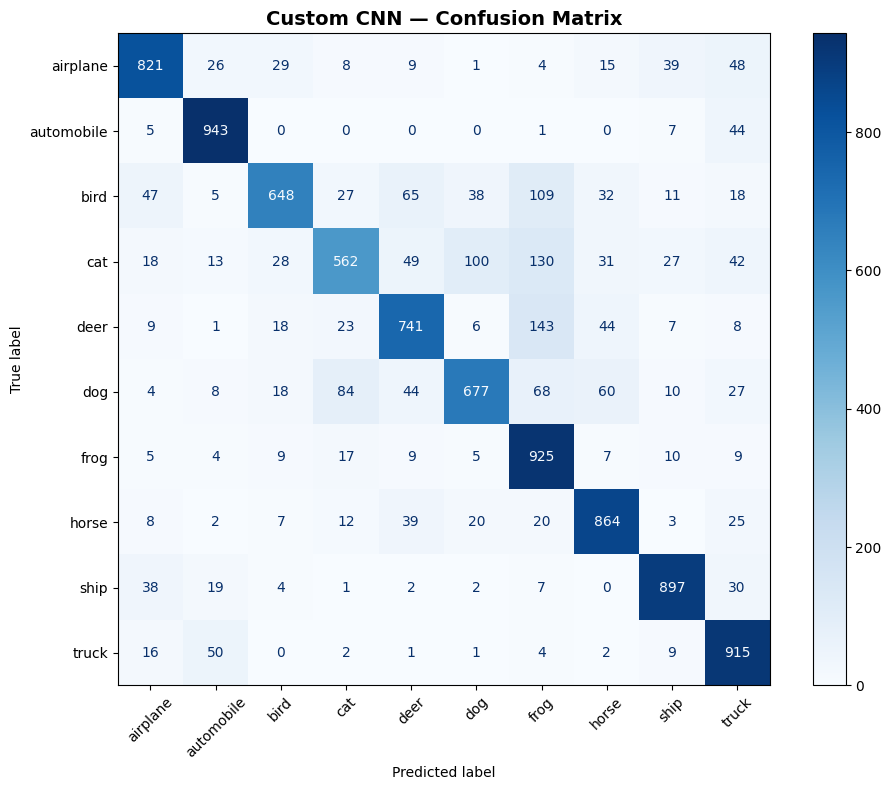


Most confused class pairs:
  • 'bird' misclassified as 'frog' — 109 times
  • 'cat' misclassified as 'frog' — 130 times
  • 'deer' misclassified as 'frog' — 143 times

Visually similar categories (e.g., cat/dog, automobile/truck) tend to exhibit higher confusion rates.


In [10]:
# Section 1.9: Evaluate Custom CNN on the hold-out test set and inspect confusion matrix

cnn_test_loss, cnn_test_acc = cnn_model.evaluate(test_ds, verbose=0)
print(f"Custom CNN — Test Loss: {cnn_test_loss:.4f}  |  Test Accuracy: {cnn_test_acc:.4f}\n")

y_pred_cnn_probs = cnn_model.predict(test_ds, verbose=0)
y_pred_cnn = np.argmax(y_pred_cnn_probs, axis=1)
y_true_classes = y_test_eval.flatten()

print("Classification Report (Custom CNN)")
print("=" * 60)
print(classification_report(y_true_classes, y_pred_cnn, target_names=CIFAR10_CLASSES))

fig, ax = plt.subplots(figsize=(10, 8))
cm_cnn = confusion_matrix(y_true_classes, y_pred_cnn)
ConfusionMatrixDisplay(confusion_matrix=cm_cnn, display_labels=CIFAR10_CLASSES).plot(
    ax=ax, cmap='Blues', xticks_rotation=45, values_format='d')
ax.set_title('Custom CNN — Confusion Matrix', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

off_diag = cm_cnn.copy(); np.fill_diagonal(off_diag, 0)
top3 = np.dstack(np.unravel_index(np.argsort(off_diag.ravel())[-3:], cm_cnn.shape))[0]
print("\nMost confused class pairs:")
for true_i, pred_i in top3:
    print(f"  • '{CIFAR10_CLASSES[true_i]}' misclassified as "
          f"'{CIFAR10_CLASSES[pred_i]}' — {cm_cnn[true_i, pred_i]} times")
print("\nVisually similar categories (e.g., cat/dog, automobile/truck) "
      "tend to exhibit higher confusion rates.")

In [11]:
# Section 1.10: Build Frozen MobileNetV2 transfer learning pipeline (upsampled to 96x96)

IMG_SIZE_TL = 96  # minimum input size accepted by MobileNetV2


def build_tl_dataset(images, labels, training=False, batch_size=BATCH_SIZE_CLF):
    labels_oh = tf.one_hot(tf.cast(labels.flatten(), tf.int32), NUM_CLASSES)
    ds = tf.data.Dataset.from_tensor_slices((images, labels_oh))
    if training:
        ds = ds.shuffle(len(images), seed=SEED)

    # resize and preprocess images
    def preprocess_img(x, y):
        x = tf.cast(x, tf.float32)
        x = tf.image.resize(x, (IMG_SIZE_TL, IMG_SIZE_TL))
        x = keras.applications.mobilenet_v2.preprocess_input(x)
        return x, y

    ds = ds.map(preprocess_img, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size)
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                     num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


train_ds_tl = build_tl_dataset(x_train, y_train, training=True)
val_ds_tl   = build_tl_dataset(x_val,   y_val,   training=False)
test_ds_tl  = build_tl_dataset(x_test_eval, y_test_eval, training=False)

base_model = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE_TL, IMG_SIZE_TL, 3),
    include_top=False,
    weights='imagenet',
)
base_model.trainable = False

tl_model = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation='softmax'),
], name="frozen_mobilenetv2")

tl_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

trainable_params   = sum(tf.keras.backend.count_params(w) for w in tl_model.trainable_weights)
frozen_params      = sum(tf.keras.backend.count_params(w) for w in tl_model.non_trainable_weights)
print(f"MobileNetV2 base layers : {len(base_model.layers)}")
print(f"Trainable params        : {trainable_params:,}")
print(f"Non-trainable params    : {frozen_params:,}")
tl_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 base layers : 154
Trainable params        : 331,018
Non-trainable params    : 2,258,496


Model: "frozen_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,589,514 (9.88 MB)

 Trainable params: 331,018 (1.26 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

Training Frozen MobileNetV2 for up to 50 epochs ...
Epoch 1/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 132s 180ms/step - accuracy: 0.6546 - loss: 1.0356 - val_accuracy: 0.8059 - val_loss: 0.5818 - learning_rate: 0.0010
Epoch 2/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 99s 158ms/step - accuracy: 0.7120 - loss: 0.8306 - val_accuracy: 0.8100 - val_loss: 0.5689 - learning_rate: 0.0010
Epoch 3/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 99s 158ms/step - accuracy: 0.7254 - loss: 0.7922 - val_accuracy: 0.8173 - val_loss: 0.5337 - learning_rate: 0.0010
Epoch 4/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 100s 159ms/step - accuracy: 0.7353 - loss: 0.7660 - val_accuracy: 0.8199 - val_loss: 0.5336 - learning_rate: 0.0010
Epoch 5/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 100s 159ms/step - accuracy: 0.7373 - loss: 0.7599 - val_accuracy: 0.8257 - val_loss: 0.5239 - learning_rate: 0.0010
Epoch 6/50
625/625 ━━━━━━━━━━━━━━━━━━━━ 142s 159ms/step - accuracy: 0.7411 - loss: 0.7525 - val_accuracy: 0.8212 - val_loss: 0.5245 - learning_rate: 0.0010
Epoch 7/50
625

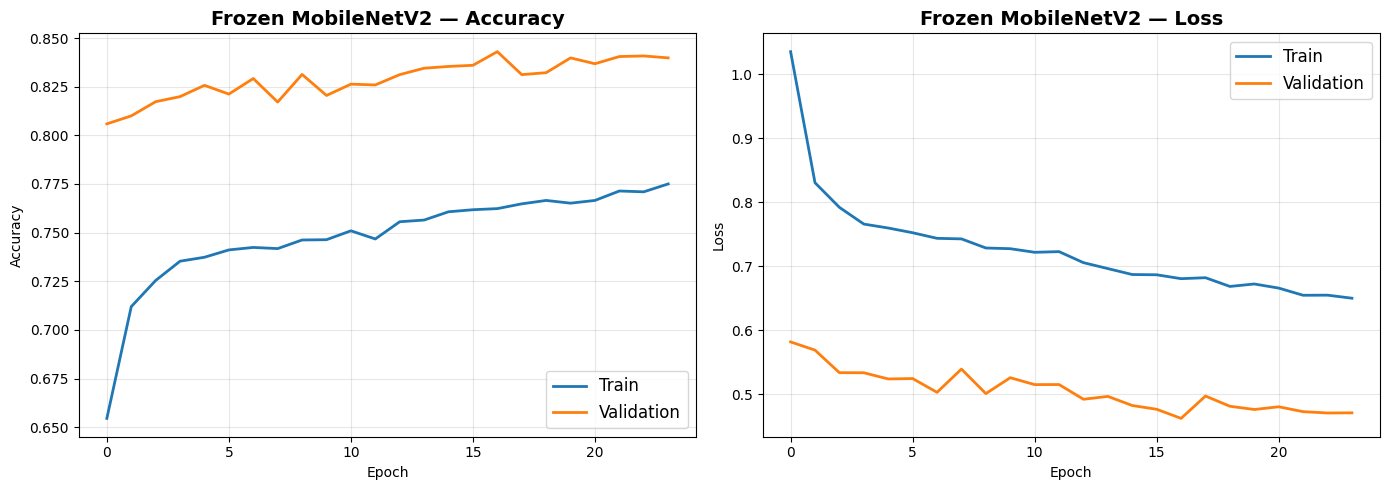


Frozen MobileNetV2 — Test Loss: 0.4488  |  Test Accuracy: 0.8419

Classification Report (Frozen MobileNetV2)
              precision    recall  f1-score   support

    airplane       0.87      0.83      0.85      1000
  automobile       0.88      0.95      0.91      1000
        bird       0.88      0.77      0.82      1000
         cat       0.77      0.69      0.73      1000
        deer       0.83      0.79      0.81      1000
         dog       0.79      0.81      0.80      1000
        frog       0.86      0.89      0.87      1000
       horse       0.81      0.87      0.84      1000
        ship       0.87      0.91      0.89      1000
       truck       0.85      0.92      0.89      1000

    accuracy                           0.84     10000
   macro avg       0.84      0.84      0.84     10000
weighted avg       0.84      0.84      0.84     10000

 COMPARISON: Custom CNN  vs  Frozen MobileNetV2
  Custom CNN          → Test Accuracy: 0.7993
  Frozen MobileNetV2  → Test Accuracy

In [12]:
# Section 1.11: Train and evaluate Frozen MobileNetV2 feature extractor against Custom CNN

tl_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=7, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
]

print(f"Training Frozen MobileNetV2 for up to {EPOCHS_CLF} epochs ...")
tl_history = tl_model.fit(
    train_ds_tl,
    validation_data=val_ds_tl,
    epochs=EPOCHS_CLF,
    callbacks=tl_callbacks,
    verbose=1,
)

plot_training_curves(tl_history, "Frozen MobileNetV2")

tl_test_loss, tl_test_acc = tl_model.evaluate(test_ds_tl, verbose=0)
print(f"\nFrozen MobileNetV2 — Test Loss: {tl_test_loss:.4f}  |  Test Accuracy: {tl_test_acc:.4f}")

y_pred_tl = np.argmax(tl_model.predict(test_ds_tl, verbose=0), axis=1)
print("\nClassification Report (Frozen MobileNetV2)")
print(classification_report(y_true_classes, y_pred_tl, target_names=CIFAR10_CLASSES))

print("=" * 58)
print(" COMPARISON: Custom CNN  vs  Frozen MobileNetV2")
print("=" * 58)
print(f"  Custom CNN          → Test Accuracy: {cnn_test_acc:.4f}")
print(f"  Frozen MobileNetV2  → Test Accuracy: {tl_test_acc:.4f}")
print("=" * 58)

Base model layers : 154
  Frozen           : 124
  Trainable        : 30

Fine-tuning MobileNetV2 for up to 20 epochs ...
Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 121s 165ms/step - accuracy: 0.6913 - loss: 0.9140 - val_accuracy: 0.8226 - val_loss: 0.5637 - learning_rate: 1.0000e-05
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 97s 154ms/step - accuracy: 0.7333 - loss: 0.7761 - val_accuracy: 0.8411 - val_loss: 0.4901 - learning_rate: 1.0000e-05
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 97s 155ms/step - accuracy: 0.7516 - loss: 0.7211 - val_accuracy: 0.8455 - val_loss: 0.4717 - learning_rate: 1.0000e-05
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 148s 164ms/step - accuracy: 0.7645 - loss: 0.6842 - val_accuracy: 0.8513 - val_loss: 0.4533 - learning_rate: 1.0000e-05
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 103s 165ms/step - accuracy: 0.7719 - loss: 0.6573 - val_accuracy: 0.8525 - val_loss: 0.4408 - learning_rate: 1.0000e-05
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 139s 160ms/step - accuracy: 0.7806 - los

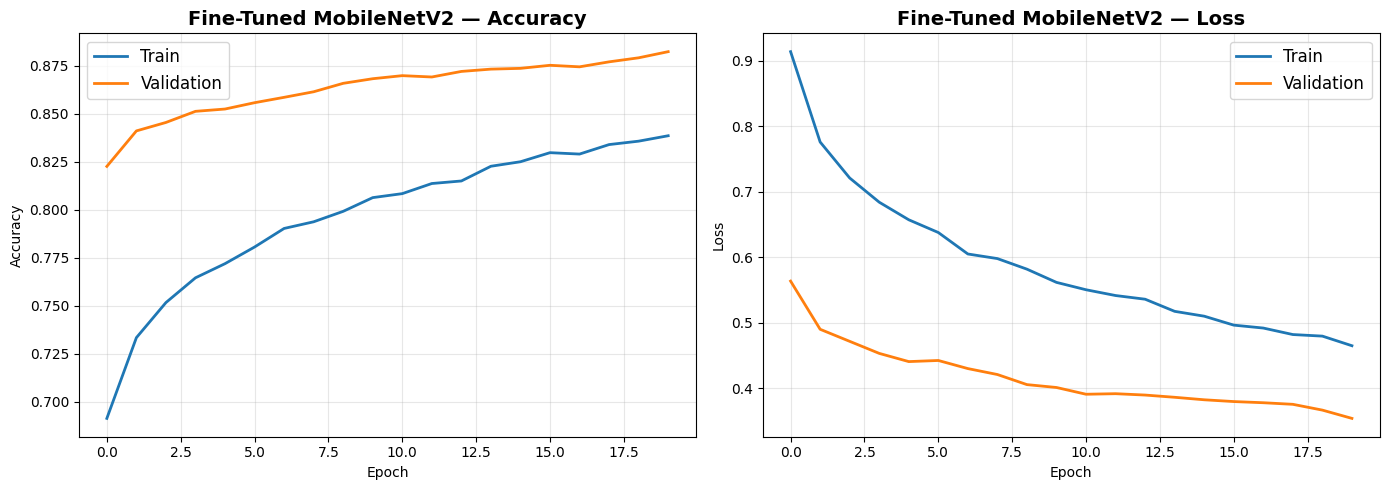


Fine-Tuned MobileNetV2 — Test Loss: 0.3468  |  Test Accuracy: 0.8831

Classification Report (Fine-Tuned MobileNetV2)
              precision    recall  f1-score   support

    airplane       0.92      0.87      0.89      1000
  automobile       0.90      0.96      0.93      1000
        bird       0.92      0.84      0.88      1000
         cat       0.83      0.73      0.77      1000
        deer       0.86      0.89      0.87      1000
         dog       0.86      0.82      0.84      1000
        frog       0.91      0.91      0.91      1000
       horse       0.87      0.93      0.90      1000
        ship       0.90      0.94      0.92      1000
       truck       0.87      0.95      0.91      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



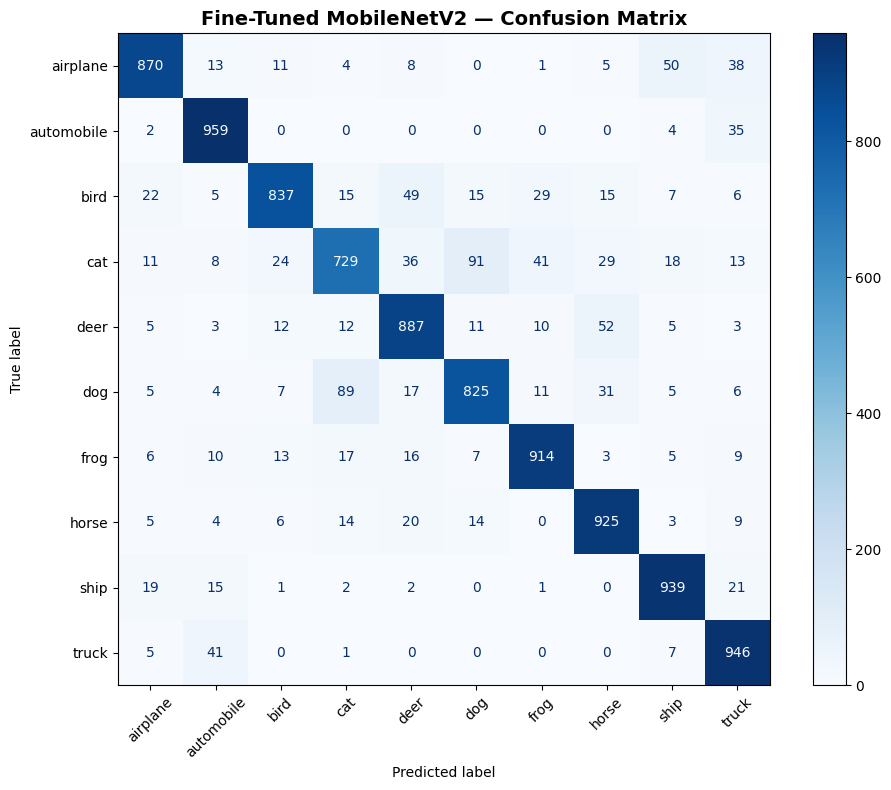

In [13]:
# Section 1.12: Fine-tune top 30 layers of MobileNetV2 at a conservative learning rate (1e-5)

base_model.trainable = True
fine_tune_from = max(0, len(base_model.layers) - 30)
for layer in base_model.layers[:fine_tune_from]:
    layer.trainable = False

trainable_count = sum(1 for l in base_model.layers if l.trainable)
frozen_count    = sum(1 for l in base_model.layers if not l.trainable)
print(f"Base model layers : {len(base_model.layers)}")
print(f"  Frozen           : {frozen_count}")
print(f"  Trainable        : {trainable_count}")

# recompile with small lr
tl_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

EPOCHS_FT = 5 if QUICK_RUN else 20

ft_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7, verbose=1),
]

print(f"\nFine-tuning MobileNetV2 for up to {EPOCHS_FT} epochs ...")
ft_history = tl_model.fit(
    train_ds_tl,
    validation_data=val_ds_tl,
    epochs=EPOCHS_FT,
    callbacks=ft_callbacks,
    verbose=1,
)

plot_training_curves(ft_history, "Fine-Tuned MobileNetV2")

ft_test_loss, ft_test_acc = tl_model.evaluate(test_ds_tl, verbose=0)
print(f"\nFine-Tuned MobileNetV2 — Test Loss: {ft_test_loss:.4f}  |  Test Accuracy: {ft_test_acc:.4f}")

y_pred_ft = np.argmax(tl_model.predict(test_ds_tl, verbose=0), axis=1)
print("\nClassification Report (Fine-Tuned MobileNetV2)")
print(classification_report(y_true_classes, y_pred_ft, target_names=CIFAR10_CLASSES))

fig, ax = plt.subplots(figsize=(10, 8))
cm_ft = confusion_matrix(y_true_classes, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=CIFAR10_CLASSES).plot(
    ax=ax, cmap='Blues', xticks_rotation=45, values_format='d')
ax.set_title('Fine-Tuned MobileNetV2 — Confusion Matrix', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

In [14]:
# Section 1.13: Aggregate test metrics into a unified CIFAR-10 benchmark comparison table

all_preds = {
    'Custom CNN':              y_pred_cnn,
    'Frozen MobileNetV2':      y_pred_tl,
    'Fine-Tuned MobileNetV2':  y_pred_ft,
}

rows = []
for name, preds in all_preds.items():
    rpt = classification_report(y_true_classes, preds, output_dict=True)
    if name == 'Custom CNN':
        loss, acc = cnn_test_loss, cnn_test_acc
    elif name == 'Frozen MobileNetV2':
        loss, acc = tl_test_loss, tl_test_acc
    else:
        loss, acc = ft_test_loss, ft_test_acc
    rows.append({
        'Model':           name,
        'Test Accuracy':   acc,
        'Test Loss':       loss,
        'Macro Precision': rpt['macro avg']['precision'],
        'Macro Recall':    rpt['macro avg']['recall'],
        'Macro F1-Score':  rpt['macro avg']['f1-score'],
    })

comparison_df = pd.DataFrame(rows)

print("=" * 85)
print("  FINAL MODEL COMPARISON — CIFAR-10 Classification")
print("=" * 85)
print(comparison_df.to_string(index=False, float_format='%.4f'))
print("=" * 85)

best = comparison_df.loc[comparison_df['Test Accuracy'].idxmax()]
print(f"\n★  Best model: {best['Model']}  (Accuracy: {best['Test Accuracy']:.4f})")

  FINAL MODEL COMPARISON — CIFAR-10 Classification
                 Model  Test Accuracy  Test Loss  Macro Precision  Macro Recall  Macro F1-Score
            Custom CNN         0.7993     0.5910           0.8049        0.7993          0.7957
    Frozen MobileNetV2         0.8419     0.4488           0.8415        0.8419          0.8405
Fine-Tuned MobileNetV2         0.8831     0.3468           0.8829        0.8831          0.8820

★  Best model: Fine-Tuned MobileNetV2  (Accuracy: 0.8831)


## Part 2 — Multi-Task Pet Head Localization & Species Classification (Oxford-IIIT Pet)

This section formulates single-object localization and binary species recognition on the **Oxford-IIIT Pet** dataset using Pascal VOC head bounding-box annotations:

- **Input:** RGB pet image resized to `128x128`.
- **Dual Prediction Heads:**
  1. `bbox_output`: Sigmoid-activated 4-D regression head predicting normalized head coordinates `[xmin, ymin, xmax, ymax]`.
  2. `species_output`: Sigmoid-activated binary classification head predicting species (`0 = Cat`, `1 = Dog`).

The pipeline covers XML bounding-box alignment, stratified `70/15/15` splitting, multi-task loss balancing (`5.0 * MSE + 1.0 * BCE`), vectorized IoU computation, thresholded detection Precision/Recall/F1 analysis, and qualitative bounding-box overlays.

In [15]:
# Section 2.1: Load Oxford-IIIT Pet dataset and parse Pascal VOC XML head bounding boxes

import xml.etree.ElementTree as ET
import urllib.request
import tarfile
import glob

PET_IMG_SIZE  = 128
BATCH_SIZE_DET = 32
EPOCHS_DET    = 15 if QUICK_RUN else 40

pet_dataset, pet_info = tfds.load(
    'oxford_iiit_pet',
    split='train',
    with_info=True,
    as_supervised=False,
)
print(f"Oxford-IIIT Pet — training examples: {pet_info.splits['train'].num_examples}")

ANNOT_URL  = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz"
ANNOT_FILE = "annotations.tar.gz"

if not os.path.isdir("annotations/xmls"):
    print("Downloading head bounding-box annotations ...")
    urllib.request.urlretrieve(ANNOT_URL, ANNOT_FILE)
    with tarfile.open(ANNOT_FILE, "r:gz") as tar:
        tar.extractall()
    print("Done.")
else:
    print("Annotations already present.")

def parse_head_bbox(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    sz   = root.find('size')
    w, h = int(sz.find('width').text), int(sz.find('height').text)
    bb   = root.find('object').find('bndbox')
    xmin = max(0.0, int(bb.find('xmin').text) / w)
    ymin = max(0.0, int(bb.find('ymin').text) / h)
    xmax = min(1.0, int(bb.find('xmax').text) / w)
    ymax = min(1.0, int(bb.find('ymax').text) / h)
    return [xmin, ymin, xmax, ymax]

bbox_dict = {}
for xf in sorted(glob.glob("annotations/xmls/*.xml")):
    stem = os.path.splitext(os.path.basename(xf))[0]
    try:
        bbox_dict[stem] = parse_head_bbox(xf)
    except Exception:
        pass

print(f"Parsed {len(bbox_dict)} head bounding-box annotations.")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

...

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.XMECOS_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Oxford-IIIT Pet — training examples: 3680


/tmp/ipykernel_13607/3231468095.py:31: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall()


Done.
Parsed 3686 head bounding-box annotations.


In [16]:
# Section 2.2: Match pet images with normalized [xmin, ymin, xmax, ymax] boxes and create 70/15/15 splits

print("Matching images with head bounding boxes ...")

images_list, bboxes_list, species_list = [], [], []
skipped = 0

for example in pet_dataset:
    fname = example['file_name'].numpy().decode('utf-8')
    stem  = os.path.splitext(fname)[0]
    if stem not in bbox_dict:
        skipped += 1
        continue
    img = tf.image.resize(example['image'], (PET_IMG_SIZE, PET_IMG_SIZE))
    img = tf.cast(img, tf.float32) / 255.0
    images_list.append(img.numpy())
    bboxes_list.append(bbox_dict[stem])
    species_list.append(int(example['species'].numpy()))

images_np  = np.array(images_list,  dtype=np.float32)
bboxes_np  = np.array(bboxes_list,  dtype=np.float32)
species_np = np.array(species_list, dtype=np.float32)

print(f"Matched samples : {len(images_np)}")
print(f"Skipped (no bbox): {skipped}")
print(f"Images shape     : {images_np.shape}")
print(f"Bboxes shape     : {bboxes_np.shape}  — [xmin, ymin, xmax, ymax] normalised")
print(f"Species shape    : {species_np.shape}  — 0=cat, 1=dog")

X_det_trainval, X_det_test, y_bb_trainval, y_bb_test, y_sp_trainval, y_sp_test = \
    train_test_split(images_np, bboxes_np, species_np,
                     test_size=0.15, stratify=species_np, random_state=SEED)

X_det_train, X_det_val, y_bb_train, y_bb_val, y_sp_train, y_sp_val = \
    train_test_split(X_det_trainval, y_bb_trainval, y_sp_trainval,
                     test_size=0.176, stratify=y_sp_trainval, random_state=SEED)
# 0.176 ≈ 0.15 / 0.85  →  ~15 % of the total for validation

if QUICK_RUN:
    cap = min(1500, len(X_det_train))
    X_det_train  = X_det_train[:cap]
    y_bb_train   = y_bb_train[:cap]
    y_sp_train   = y_sp_train[:cap]

print(f"\nDetection splits  —  Train: {len(X_det_train)}  |  Val: {len(X_det_val)}  |  Test: {len(X_det_test)}")

def build_det_dataset(images, bboxes, species, training=False):
    targets = {'bbox_output': bboxes, 'species_output': species}
    ds = tf.data.Dataset.from_tensor_slices((images, targets))
    if training:
        ds = ds.shuffle(len(images), seed=SEED)
    ds = ds.batch(BATCH_SIZE_DET)
    return ds.prefetch(AUTOTUNE)

train_det_ds = build_det_dataset(X_det_train, y_bb_train, y_sp_train, training=True)
val_det_ds   = build_det_dataset(X_det_val,   y_bb_val,   y_sp_val)
test_det_ds  = build_det_dataset(X_det_test,  y_bb_test,  y_sp_test)

for imgs, tgts in train_det_ds.take(1):
    print(f"\nBatch check — images: {imgs.shape}, "
          f"bbox: {tgts['bbox_output'].shape}, species: {tgts['species_output'].shape}")

Matching images with head bounding boxes ...
Matched samples : 3671
Skipped (no bbox): 9
Images shape     : (3671, 128, 128, 3)
Bboxes shape     : (3671, 4)  — [xmin, ymin, xmax, ymax] normalised
Species shape    : (3671,)  — 0=cat, 1=dog

Detection splits  —  Train: 2570  |  Val: 550  |  Test: 551

Batch check — images: (32, 128, 128, 3), bbox: (32, 4), species: (32,)


Species Distribution
Species  Train  Val  Test  Total
    Cat    827  177   177   1181
    Dog   1743  373   374   2490


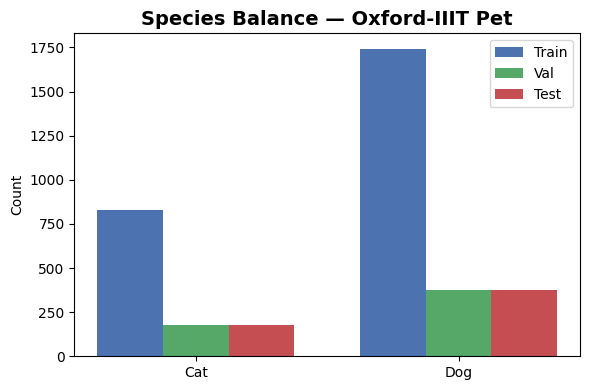

In [17]:
# Section 2.3: Inspect binary species distribution (Cat vs. Dog) across splits

PET_SPECIES = ['Cat', 'Dog']

sp_counts = pd.DataFrame({
    'Species': PET_SPECIES,
    'Train': [np.sum(y_sp_train == i) for i in range(2)],
    'Val':   [np.sum(y_sp_val   == i) for i in range(2)],
    'Test':  [np.sum(y_sp_test  == i) for i in range(2)],
})
sp_counts['Total'] = sp_counts['Train'] + sp_counts['Val'] + sp_counts['Test']

print("Species Distribution")
print("=" * 50)
print(sp_counts.to_string(index=False))
print("=" * 50)

fig, ax = plt.subplots(figsize=(6, 4))
x_pos = np.arange(2)
width = 0.25
ax.bar(x_pos - width, sp_counts['Train'], width, label='Train', color='#4C72B0')
ax.bar(x_pos,         sp_counts['Val'],   width, label='Val',   color='#55A868')
ax.bar(x_pos + width, sp_counts['Test'],  width, label='Test',  color='#C44E52')
ax.set_xticks(x_pos); ax.set_xticklabels(PET_SPECIES)
ax.set_title('Species Balance — Oxford-IIIT Pet', fontsize=14, fontweight='bold')
ax.set_ylabel('Count'); ax.legend()
plt.tight_layout(); plt.show()

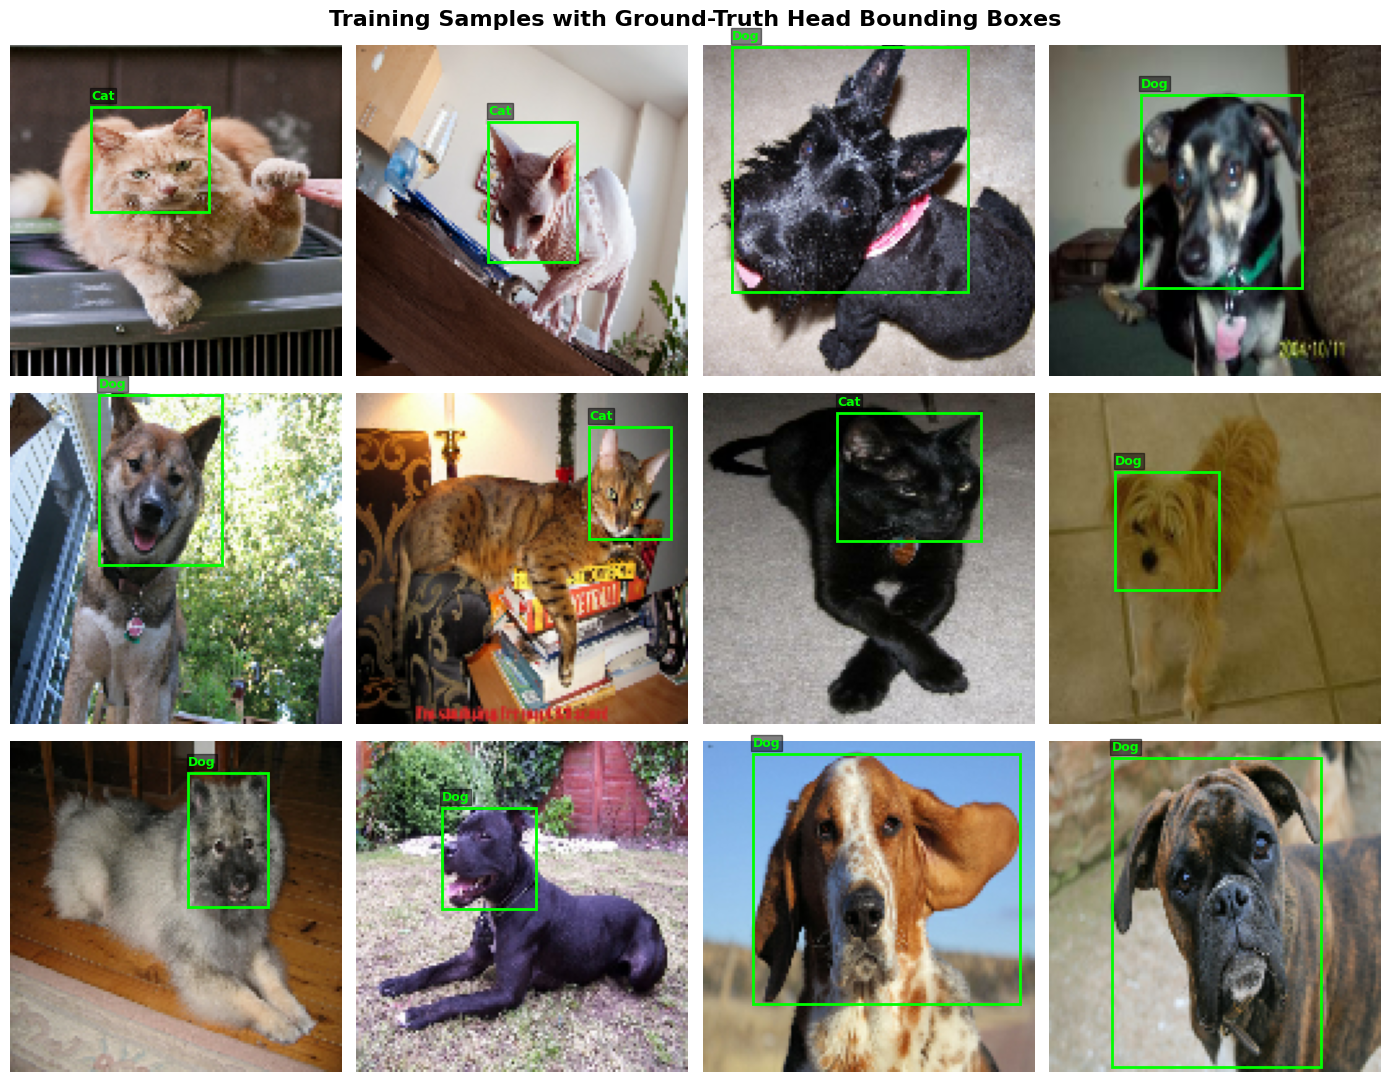

In [18]:
# Section 2.4: Visualize training samples overlaid with ground-truth head bounding boxes

def draw_bbox(ax, bbox, color='lime', lw=2, label=None):
    h, w = PET_IMG_SIZE, PET_IMG_SIZE
    x0, y0, x1, y1 = bbox[0]*w, bbox[1]*h, bbox[2]*w, bbox[3]*h
    rect = plt.Rectangle((x0, y0), x1-x0, y1-y0,
                          linewidth=lw, edgecolor=color, facecolor='none')
    ax.add_patch(rect)
    if label:
        ax.text(x0, y0-3, label, color=color, fontsize=9, fontweight='bold',
                bbox=dict(facecolor='black', alpha=0.5, pad=1))

fig, axes = plt.subplots(3, 4, figsize=(14, 11))
indices = np.random.choice(len(X_det_train), size=12, replace=False)
for ax, idx in zip(axes.flat, indices):
    ax.imshow(X_det_train[idx])
    sp_label = PET_SPECIES[int(y_sp_train[idx])]
    draw_bbox(ax, y_bb_train[idx], color='lime', label=sp_label)
    ax.axis('off')
fig.suptitle('Training Samples with Ground-Truth Head Bounding Boxes',
             fontsize=16, fontweight='bold')
plt.tight_layout(); plt.show()

In [19]:
# Section 2.5: Define dual-head MobileNetV2 multi-task detector and vectorized IoU metric

def compute_iou(pred, true):
    xi1 = np.maximum(pred[:, 0], true[:, 0])
    yi1 = np.maximum(pred[:, 1], true[:, 1])
    xi2 = np.minimum(pred[:, 2], true[:, 2])
    yi2 = np.minimum(pred[:, 3], true[:, 3])
    inter = np.maximum(0, xi2 - xi1) * np.maximum(0, yi2 - yi1)
    area_p = (pred[:, 2] - pred[:, 0]) * (pred[:, 3] - pred[:, 1])
    area_t = (true[:, 2] - true[:, 0]) * (true[:, 3] - true[:, 1])
    union  = area_p + area_t - inter
    return inter / (union + 1e-7)

det_backbone = keras.applications.MobileNetV2(
    input_shape=(PET_IMG_SIZE, PET_IMG_SIZE, 3),
    include_top=False,
    weights='imagenet',
)
det_backbone.trainable = False   # freeze backbone initially

inputs = keras.Input(shape=(PET_IMG_SIZE, PET_IMG_SIZE, 3), name='input_image')
# Rescale [0,1] → [-1,1] expected by MobileNetV2
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
x = det_backbone(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)

# Bounding-box regression head  (4 coords in [0,1])
bb = layers.Dense(128, activation='relu', name='bb_hidden')(x)
bbox_output = layers.Dense(4, activation='sigmoid', name='bbox_output')(bb)

# Species classification head  (binary)
sp = layers.Dense(64, activation='relu', name='sp_hidden')(x)
species_output = layers.Dense(1, activation='sigmoid', name='species_output')(sp)

det_model = keras.Model(inputs=inputs,
                        outputs={'bbox_output': bbox_output,
                                 'species_output': species_output},
                        name='pet_detector')
det_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "pet_detector"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 128, 128,  │          0 │ input_image[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_1… │ (None, 4, 4,      │  2,257,984 │ rescaling[0][0]   │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 256)       │    327,936 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256)       │      1,024 │ dense_4[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bb_hidden (Dense)   │ (None, 128)       │     32,896 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sp_hidden (Dense)   │ (None, 64)        │     16,448 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bbox_output (Dense) │ (None, 4)         │        516 │ bb_hidden[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ species_output      │ (None, 1)         │         65 │ sp_hidden[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,636,869 (10.06 MB)

 Trainable params: 378,373 (1.44 MB)

 Non-trainable params: 2,258,496 (8.62 MB)

In [20]:
# Section 2.6: Compile with weighted multi-task loss (5.0 * MSE + 1.0 * BCE) and train detector

det_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss={
        'bbox_output':    'mse',
        'species_output': 'binary_crossentropy',
    },
    loss_weights={
        'bbox_output':    5.0,
        'species_output': 1.0,
    },
    metrics={
        'species_output': ['accuracy'],
    },
)

det_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1),
]

print(f"Training Pet Detector for up to {EPOCHS_DET} epochs ...")
det_history = det_model.fit(
    train_det_ds,
    validation_data=val_det_ds,
    epochs=EPOCHS_DET,
    callbacks=det_callbacks,
    verbose=1,
)

Training Pet Detector for up to 40 epochs ...
Epoch 1/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 53s 415ms/step - bbox_output_loss: 0.0448 - loss: 0.3344 - species_output_accuracy: 0.9599 - species_output_loss: 0.1093 - val_bbox_output_loss: 0.0313 - val_loss: 0.2628 - val_species_output_accuracy: 0.9673 - val_species_output_loss: 0.1032 - learning_rate: 0.0010
Epoch 2/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - bbox_output_loss: 0.0236 - loss: 0.1481 - species_output_accuracy: 0.9918 - species_output_loss: 0.0303 - val_bbox_output_loss: 0.0214 - val_loss: 0.1595 - val_species_output_accuracy: 0.9873 - val_species_output_loss: 0.0500 - learning_rate: 0.0010
Epoch 3/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - bbox_output_loss: 0.0189 - loss: 0.1156 - species_output_accuracy: 0.9914 - species_output_loss: 0.0214 - val_bbox_output_loss: 0.0198 - val_loss: 0.1485 - val_species_output_accuracy: 0.9855 - val_species_output_loss: 0.0467 - learning_rate: 0.0010
Epoch 4/40
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 18

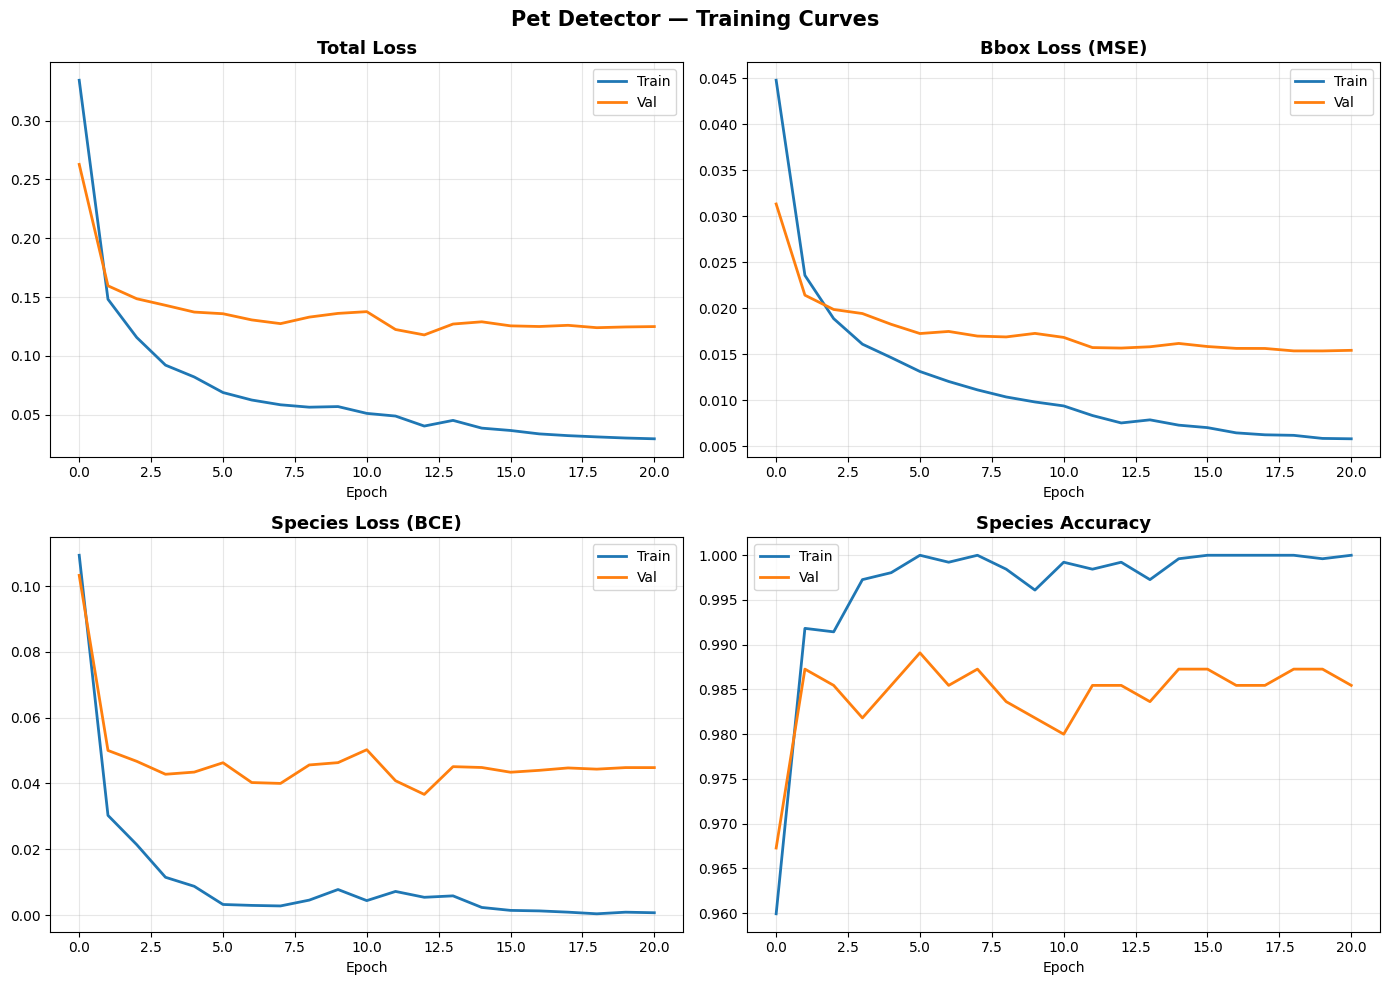

In [21]:
# Section 2.7: Plot multi-task training & validation curves (total loss, bbox MSE, species BCE & accuracy)

hist = det_history.history
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(hist['loss'],     label='Train', linewidth=2)
axes[0, 0].plot(hist['val_loss'], label='Val',   linewidth=2)
axes[0, 0].set_title('Total Loss', fontsize=13, fontweight='bold')
axes[0, 0].legend(); axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(hist['bbox_output_loss'],     label='Train', linewidth=2)
axes[0, 1].plot(hist['val_bbox_output_loss'], label='Val',   linewidth=2)
axes[0, 1].set_title('Bbox Loss (MSE)', fontsize=13, fontweight='bold')
axes[0, 1].legend(); axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(hist['species_output_loss'],     label='Train', linewidth=2)
axes[1, 0].plot(hist['val_species_output_loss'], label='Val',   linewidth=2)
axes[1, 0].set_title('Species Loss (BCE)', fontsize=13, fontweight='bold')
axes[1, 0].legend(); axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(hist['species_output_accuracy'],     label='Train', linewidth=2)
axes[1, 1].plot(hist['val_species_output_accuracy'], label='Val',   linewidth=2)
axes[1, 1].set_title('Species Accuracy', fontsize=13, fontweight='bold')
axes[1, 1].legend(); axes[1, 1].grid(True, alpha=0.3)

for ax in axes.flat:
    ax.set_xlabel('Epoch')
plt.suptitle('Pet Detector — Training Curves', fontsize=15, fontweight='bold')
plt.tight_layout(); plt.show()

In [22]:
# Section 2.8: Evaluate test-set Mean/Median IoU, thresholded Precision/Recall/F1, and species classification

preds = det_model.predict(test_det_ds, verbose=0)
pred_bboxes  = preds['bbox_output']
pred_species = (preds['species_output'].flatten() >= 0.5).astype(int)

ious = compute_iou(pred_bboxes, y_bb_test)

print("=" * 60)
print("  DETECTION EVALUATION RESULTS")
print("=" * 60)
print(f"  Mean IoU   : {ious.mean():.4f}")
print(f"  Median IoU : {np.median(ious):.4f}")
print(f"  Std IoU    : {ious.std():.4f}")
print()

print(f"  {'IoU Thr':>8s}  {'Precision':>10s}  {'Recall':>8s}  {'F1':>8s}")
print("  " + "-" * 40)
for thr in [0.3, 0.5, 0.75]:
    hits = (ious >= thr)
    prec = hits.sum() / len(hits)
    rec  = prec   # single-object: precision == recall
    f1   = 2 * prec * rec / (prec + rec + 1e-7)
    print(f"  {thr:>8.2f}  {prec:>10.4f}  {rec:>8.4f}  {f1:>8.4f}")
print()

print("Species Classification Report")
print(classification_report(y_sp_test.astype(int), pred_species,
                            target_names=PET_SPECIES))

  DETECTION EVALUATION RESULTS
  Mean IoU   : 0.4177
  Median IoU : 0.4473
  Std IoU    : 0.2226

   IoU Thr   Precision    Recall        F1
  ----------------------------------------
      0.30      0.7151    0.7151    0.7151
      0.50      0.4047    0.4047    0.4047
      0.75      0.0436    0.0436    0.0436

Species Classification Report
              precision    recall  f1-score   support

         Cat       0.98      0.97      0.97       177
         Dog       0.98      0.99      0.99       374

    accuracy                           0.98       551
   macro avg       0.98      0.98      0.98       551
weighted avg       0.98      0.98      0.98       551



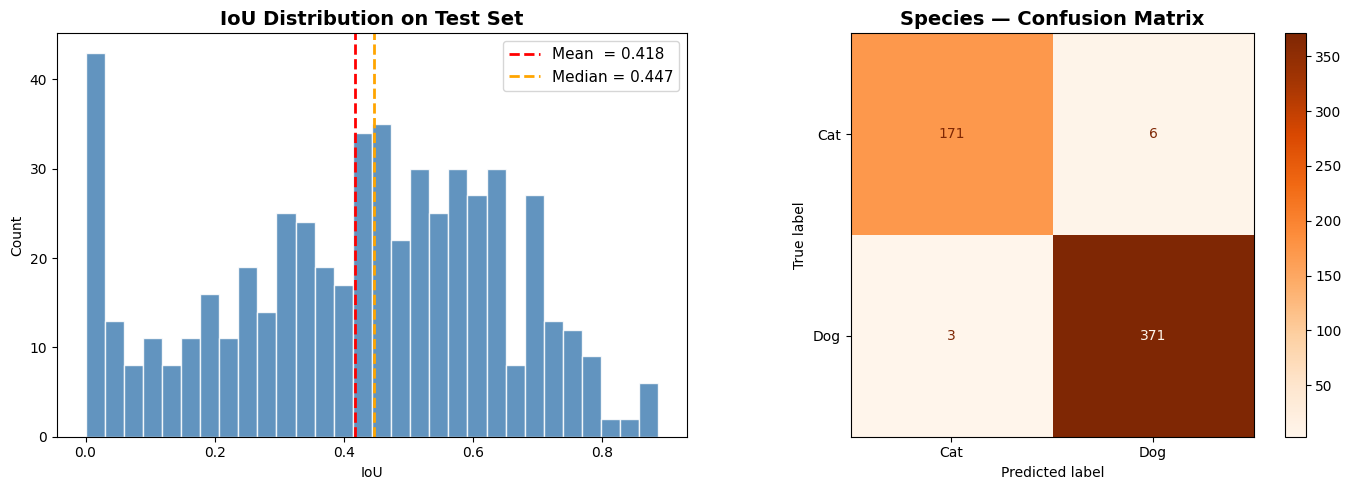

In [23]:
# Section 2.9: Plot test-set IoU distribution histogram and binary species confusion matrix

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.hist(ious, bins=30, color='steelblue', edgecolor='white', alpha=0.85)
ax1.axvline(ious.mean(),    color='red',    ls='--', lw=2, label=f'Mean  = {ious.mean():.3f}')
ax1.axvline(np.median(ious), color='orange', ls='--', lw=2, label=f'Median = {np.median(ious):.3f}')
ax1.set_title('IoU Distribution on Test Set', fontsize=14, fontweight='bold')
ax1.set_xlabel('IoU'); ax1.set_ylabel('Count'); ax1.legend(fontsize=11)

cm_sp = confusion_matrix(y_sp_test.astype(int), pred_species)
ConfusionMatrixDisplay(confusion_matrix=cm_sp, display_labels=PET_SPECIES).plot(
    ax=ax2, cmap='Oranges', values_format='d')
ax2.set_title('Species — Confusion Matrix', fontsize=14, fontweight='bold')

plt.tight_layout(); plt.show()

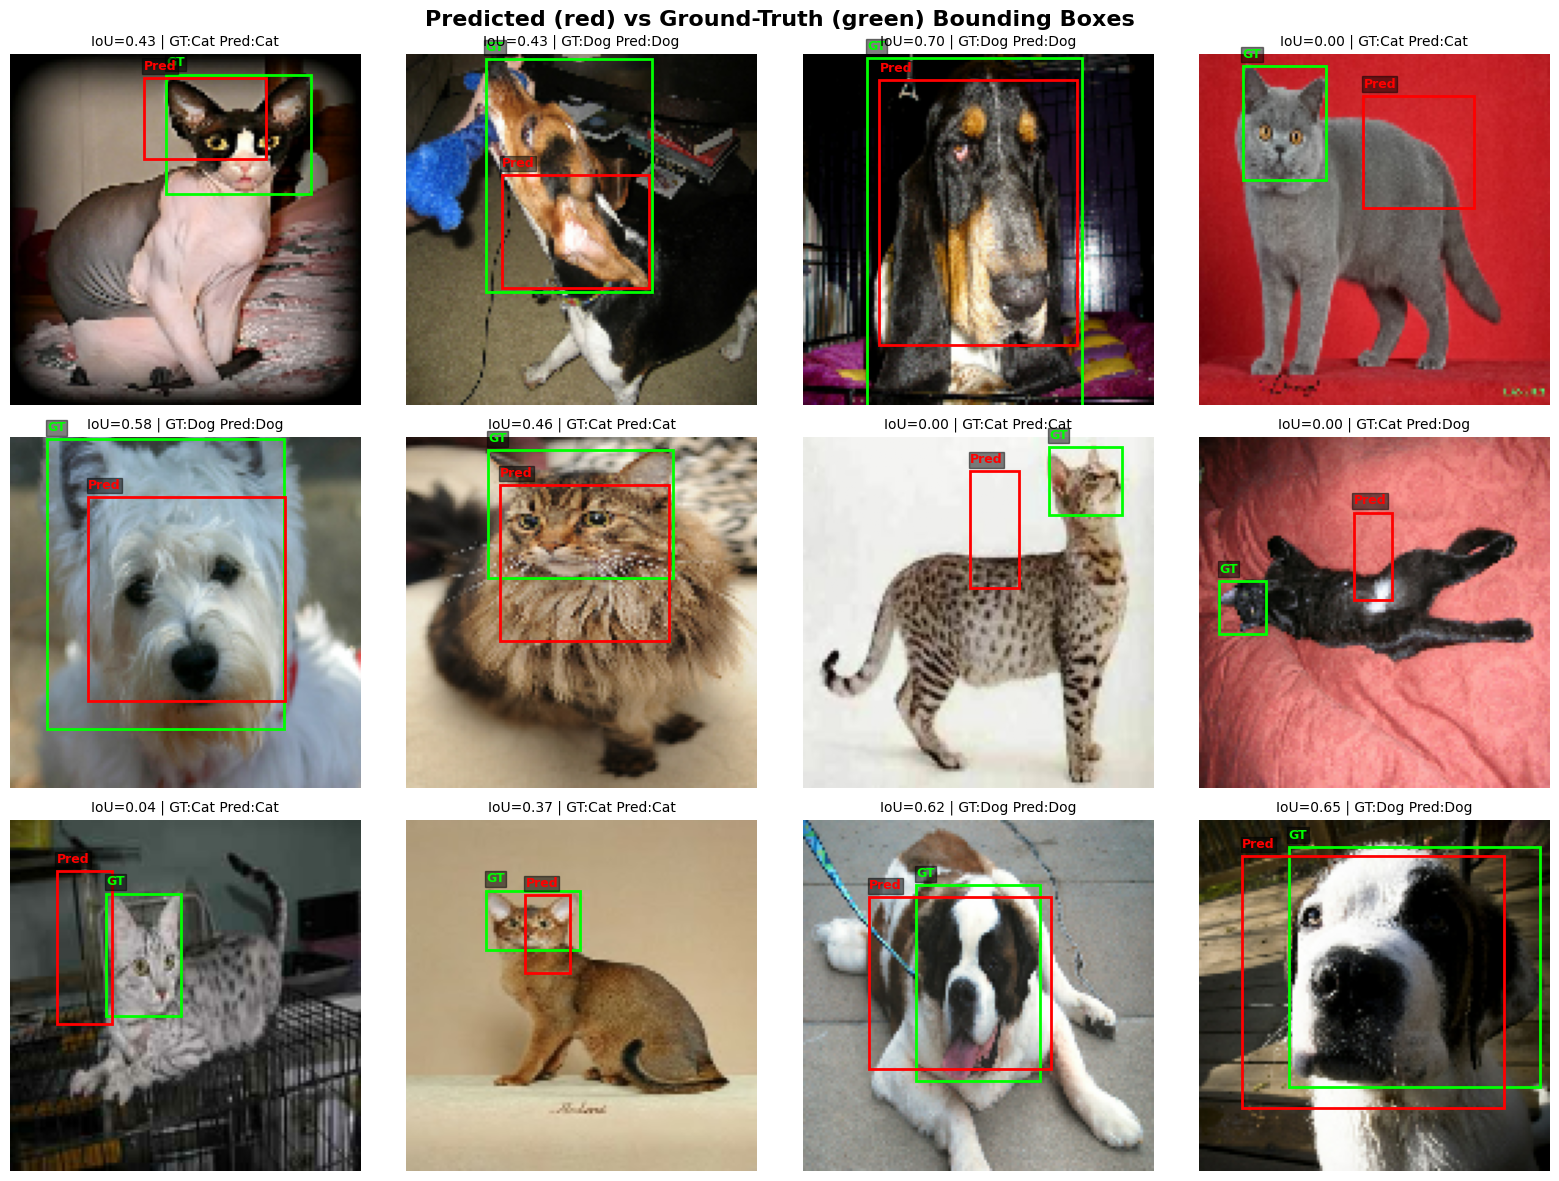

In [24]:
# Section 2.10: Visualize predicted (red) vs. ground-truth (green) bounding boxes on test samples

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
indices = np.random.choice(len(X_det_test), size=12, replace=False)

for ax, idx in zip(axes.flat, indices):
    ax.imshow(X_det_test[idx])
    draw_bbox(ax, y_bb_test[idx],    color='lime',  lw=2, label='GT')
    draw_bbox(ax, pred_bboxes[idx],  color='red',   lw=2, label='Pred')
    iou_val = ious[idx]
    true_sp = PET_SPECIES[int(y_sp_test[idx])]
    pred_sp = PET_SPECIES[pred_species[idx]]
    ax.set_title(f'IoU={iou_val:.2f} | GT:{true_sp} Pred:{pred_sp}', fontsize=10)
    ax.axis('off')

fig.suptitle('Predicted (red) vs Ground-Truth (green) Bounding Boxes',
             fontsize=16, fontweight='bold')
plt.tight_layout(); plt.show()

## Architectural Insights & Error Analysis

### 1. Transfer Learning Hierarchy & Domain Adaptation (CIFAR-10)

| Architecture | Input Resolution | Trainable Params | Test Loss | Test Accuracy | Macro F1 |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Custom 3-Block VGG CNN** | `32 x 32` | `815,530` | `0.5910` | `79.93%` | `0.7957` |
| **Frozen MobileNetV2** | `96 x 96` | `331,018` | `0.4488` | `84.19%` | `0.8405` |
| **Fine-Tuned MobileNetV2 (Top 30 Layers)** | `96 x 96` | `~1.85M` | `0.3468` | **`88.31%`** | **`0.8820`** |

- **From-Scratch Capacity vs. Sample Efficiency:** Training the 3-block VGG-style CNN from random initialization on `40,000` tiny `32x32` images reaches `79.93%` test accuracy, as the network must learn both low-level edge/color filters and high-level part detectors simultaneously from coarse spatial grids.
- **Frozen Pretrained Representations (`+4.26%`):** Upsampling CIFAR-10 images to `96x96` and extracting features via frozen ImageNet-pretrained MobileNetV2 blocks elevates test accuracy to `84.19%` while updating fewer parameters (`331K` vs. `816K`). However, locking the backbone to high-resolution ImageNet statistics limits adaptation to bilinearly upsampled `32x32` textures.
- **Selective Upper-Layer Fine-Tuning (`+8.38%` over Custom CNN):** Unfreezing the top 30 MobileNetV2 layers while keeping the bottom 124 early/mid-level feature extractors frozen—paired with a conservative `1e-5` Adam learning rate—adapts semantic filters to CIFAR-10 without catastrophic forgetting, lowering test loss to `0.3468` and achieving **`88.31%`** accuracy.

---

### 2. Regularization Effect of Online Data Augmentation

Combining online geometric perturbations (`RandomFlip("horizontal")`, `RandomRotation(0.1)`, `RandomZoom(0.1)`, `RandomTranslation(0.1, 0.1)`) with `BatchNormalization` and progressive `Dropout` (`0.2 -> 0.3 -> 0.4 -> 0.5`) effectively suppressed overfitting across 50-epoch schedules. Throughout training, training accuracy remained slightly below validation accuracy (e.g., `83.86%` train vs. `88.24%` validation at Epoch 20 for Fine-Tuned MobileNetV2) because stochastic augmentation and dropout regularize training passes exclusively, translating directly to `88.31%` generalization on the held-out test split.

---

### 3. Confusion Matrix Diagnostics & Low-Resolution Background-Texture Bias

Inspection of the **Custom CNN** confusion matrix uncovers a pronounced asymmetric error mode centered on false-positive predictions toward **`frog`** (`recall = 0.93`, `precision = 0.66`):

- **`deer -> frog`:** `143` misclassifications (largest off-diagonal cell in Custom CNN)
- **`cat -> frog`:** `130` misclassifications
- **`bird -> frog`:** `109` misclassifications

At native `32x32` resolution, fine anatomical cues (antlers, beaks, feline ears) span only a few pixels, whereas **earthy green/brown foliage, grass, and mottled natural background textures** dominate the receptive field. A shallow CNN trained from scratch latches onto these shared natural background color-texture statistics and over-predicts `frog` whenever small animals appear against outdoor clutter (alongside secondary fine-grained confusions such as `cat <-> dog`). Fine-tuning ImageNet-pretrained MobileNetV2 largely eliminates this background-texture shortcut—cutting `deer -> frog` errors from **`143` down to `10`**, `cat -> frog` from **`130` to `41`**, and `bird -> frog` from **`109` to `29`**, boosting **`frog` precision from `0.66` to `0.91`** and leaving genuine semantic cousins (`cat <-> dog`, `91` / `89`) as the primary residual confusion.

---

### 4. Multi-Task Asymmetry & The `GlobalAveragePooling2D` Spatial Bottleneck

On the **Oxford-IIIT Pet** dual-head detector, performance diverges sharply between semantic classification and coordinate regression:

- **Species Classification Head:** Reaches **`98.0%` test accuracy** (`Cat` F1 = `0.97`, `Dog` F1 = `0.99`; only `9` errors across `551` test images), benefiting directly from ImageNet's rich cat/dog breed representations.
- **Head Bounding-Box Regression Head:** Achieves **`Mean IoU = 0.4177`** (`Median IoU = 0.4473`, `Std IoU = 0.2226`).

**Root Architectural Cause (`GlobalAveragePooling2D`):** Before the shared dense trunk, MobileNetV2 outputs a `4 x 4 x 1280` spatial feature grid. Applying `GlobalAveragePooling2D()` collapses all `4 x 4 = 16` spatial cells into a single translation-invariant `1280`-D vector. While translation invariance is ideal for whole-image species classification, **averaging out spatial axes discards explicit `(x, y)` coordinate geometry**. Visually, qualitative test overlays confirm that close-up, centered pet portraits achieve strong overlap (`IoU = 0.58 - 0.70`), whereas full-body shots with small, off-center heads pull predicted boxes toward the animal's body centroid (`IoU < 0.10`).

---

### 5. IoU Threshold Sensitivity vs. Classification Accuracy

| Evaluation Metric | Value | Engineering Interpretation |
| :--- | :---: | :--- |
| **Species Test Accuracy** | `98.00%` | Confirms semantic recognition only; invariant to bounding-box drift |
| **Mean / Median IoU** | `0.4177` / `0.4473` | Captures continuous spatial overlap quality across all 551 test instances |
| **Detection F1 @ `IoU >= 0.30`** | `71.51%` | Coarse head region localized in ~7 out of 10 test images |
| **Detection F1 @ `IoU >= 0.50`** | `40.47%` | Standard PASCAL VOC benchmark; reflects centroid pull on small/off-center heads |
| **Detection F1 @ `IoU >= 0.75`** | `4.36%` | Strict COCO-grade alignment; exposes spatial pooling resolution limits |

Relying on classification accuracy (`98%`) alone masks localization drift. Evaluating across IoU thresholds demonstrates why preserving spatial feature maps before regression (e.g., `1x1 Conv2D` channel compression + `Flatten` over the `4x4` or `8x8` grid), replacing `MSE` with scale-invariant **GIoU / CIoU loss**, and fine-tuning upper backbone blocks with bbox-aware augmentations are critical next steps for tight coordinate regression.